In [1]:
# =============================================================================
# 06 - EDA OF THE ML-READY DATASET: county x NOAA storm episode (processed/model_table/)
# Summary of results lives in reports/06_ml_dataset_eda_summary.md.
# Feature-target relationships use TRAINING rows only (2017-2023), so validation and test stay unseen.
# Feature distributions are compared across all splits (features only; 2025 labels are never read).
# Inputs: processed/model_table/ (from notebook 04). Outputs: reports/ml_eda_tables/, reports/figures/ml_eda/
# =============================================================================

In [2]:
# ---- 0. Setup ---------------------------------------------------------------
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "reports" / "ml_eda_tables"
FIGS = ROOT / "reports" / "figures" / "ml_eda"
for folder in [TABLES, FIGS]:
    folder.mkdir(parents=True, exist_ok=True)

# Inputs: the local file when it is in the repo, otherwise streamed from the Hugging Face dataset
HF_DATASET = "hf://datasets/DSCI-Capstone/county-outage-data"


def src(rel):
    """Local path if the file is in the repo, otherwise its hf:// URL."""
    local = ROOT / rel
    return local.as_posix() if local.exists() else f"{HF_DATASET}/{rel}"


train = pd.read_parquet(src("processed/model_table/train.parquet"))
val = pd.read_parquet(src("processed/model_table/validation.parquet"))
test = pd.read_parquet(src("processed/model_table/test_features.parquet"))   # features only

ID_COLS = ["fips", "episode_id", "state_abbr", "fema_region", "year", "t0"]
FEATURES = [c for c in test.columns if c not in ID_COLS]
RETRO = [c for c in train.columns if c.startswith("retro_")]
assert len(FEATURES) == 36 and not set(FEATURES) & set(RETRO)
BASE = train["target"].mean()   # training positive rate

# Chart style (same as notebook 03): light surface, recessive grid, blue = main series, gray = reference
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})


def save(fig, name):
    """Save a figure to reports/figures/ml_eda and show it."""
    fig.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def as_num(s):
    """Feature column -> float (booleans and nullable ints included)."""
    return pd.to_numeric(s.astype("float64") if s.dtype == bool else s, errors="coerce").astype(float)


print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,} rows; {len(FEATURES)} features; base rate {BASE:.3f}")

train 208,482 | validation 31,064 | test 32,098 rows; 36 features; base rate 0.141


In [3]:
# ---- 1. Dataset at a glance --------------------------------------------------------
overview = pd.DataFrame([
    {"split": name, "years": f"{d['year'].min()}-{d['year'].max()}", "rows": len(d),
     "counties": d["fips"].nunique(), "episodes": d["episode_id"].nunique(), "states": d["state_abbr"].nunique(),
     "positive_rate": d["target"].mean() if "target" in d else np.nan}
    for name, d in [("train", train), ("validation", val), ("test", test)]
])
overview.to_csv(TABLES / "dataset_overview.csv", index=False)

# Rows and positive rate per year (2025 labels are not read)
by_year = pd.concat([train, val, test])[["year"]].value_counts().sort_index().rename("rows").reset_index()
by_year["positive_rate"] = by_year["year"].map(pd.concat([train, val]).groupby("year")["target"].mean())
by_year.to_csv(TABLES / "rows_by_year.csv", index=False)
overview

,split,years,rows,counties,episodes,states,positive_rate
0,train,2017-2023,208482,3073,54580,49,0.141278
1,validation,2024-2024,31064,3023,7734,49,0.164821
2,test,2025-2025,32098,3014,7866,49,NaN


In [4]:
# ---- 2. Feature dictionary + statistics ------------------------------------------
# Meaning of every column (written from notebook 04's code), with statistics from the training rows.
DICT = {
    # id / split
    "fips": ("id", "text", "5-digit county FIPS code (Census 2023)"),
    "episode_id": ("id", "integer", "NOAA Storm Events EPISODE_ID (one storm system)"),
    "state_abbr": ("id", "text", "State postal code (lower 48 + DC)"),
    "fema_region": ("id", "1-10", "FEMA region of the county"),
    "year": ("id", "year", "UTC year of t0; sets the split (train 2017-2023, validation 2024, test 2025)"),
    "t0": ("id", "UTC time", "Begin time of the episode's first report in this county"),
    # storm
    "n_events": ("storm", "count", "Storm reports in this county during the episode (drought/heat excluded)"),
    "n_tstm_wind": ("storm", "count", "Reports of type Thunderstorm Wind"),
    "n_hail": ("storm", "count", "Reports of type Hail"),
    "n_tornado": ("storm", "count", "Reports of type Tornado or Funnel Cloud"),
    "n_high_wind": ("storm", "count", "Reports of type High Wind or Strong Wind"),
    "n_flood": ("storm", "count", "Flash Flood, Flood, Heavy Rain, Coastal/Lakeshore Flood, Storm Surge/Tide, Debris Flow"),
    "n_winter": ("storm", "count", "Winter Weather, Winter Storm, Heavy Snow, Blizzard, Lake-Effect Snow, Sleet"),
    "n_ice_storm": ("storm", "count", "Reports of type Ice Storm"),
    "n_tropical": ("storm", "count", "Tropical Storm, Hurricane (Typhoon), Tropical Depression"),
    "n_cold": ("storm", "count", "Extreme Cold/Wind Chill, Cold/Wind Chill, Frost/Freeze"),
    "n_lightning": ("storm", "count", "Reports of type Lightning"),
    "n_wildfire": ("storm", "count", "Reports of type Wildfire"),
    "n_other": ("storm", "count", "Any other event type (e.g. Dense Fog, Rip Current, Dust Storm)"),
    "n_county_coded": ("storm", "count", "Reports NOAA located by county (CZ_TYPE = C)"),
    "n_zone_coded": ("storm", "count", "Reports issued for an NWS forecast zone, mapped to counties with the dated crosswalk"),
    "share_zone_coded": ("storm", "0-1", "n_zone_coded / n_events"),
    "any_partial_county": ("storm", "boolean", "At least one zone report whose zone covers only part of the county"),
    "max_wind_kts": ("storm", "knots", "Highest wind magnitude among the reports (measured or estimated); empty if none reported"),
    "max_hail_in": ("storm", "inches", "Largest hail size among Hail reports; empty if no hail"),
    "max_hurricane_cat": ("storm", "0-5", "Highest Saffir-Simpson category reported; almost always empty"),
    "county_episode_hours": ("storm", "hours", "First report begin to last report end in this county"),
    "episode_counties": ("storm", "count", "Counties touched by the whole episode (storm-system size)"),
    "log_episode_counties": ("storm", "log10", "log10(episode_counties)"),
    "episode_states": ("storm", "count", "States touched by the whole episode"),
    "episode_events": ("storm", "count", "Distinct reports in the whole episode, all counties"),
    # time
    "month": ("time", "1-12", "Month of t0 (UTC)"),
    "local_hour": ("time", "0-23", "Hour of t0 in local standard time (state's main time zone)"),
    # county
    "log_customers": ("county", "log10", "log10 of customers served: EAGLE-I MCC, or Census population x 0.508 where MCC is broken (all NC + 30 counties)"),
    "log_pop": ("county", "log10", "log10 of Census 2023 county population; empty for Connecticut's 8 old counties"),
    "dqi": ("county", "0-100", "EAGLE-I data quality index of the FEMA region (2018-2022 values; 2017 uses 2018, 2023+ use 2022)"),
    "pct_customers_tracked": ("county", "0-1", "Share of the state's customers EAGLE-I tracks (same year mapping as dqi)"),
    # pre-storm
    "pre_peak_24h": ("pre-storm", "0-1", "Worst share of customers out in the 24 h before the start hour; empty if the day before wasn't observed"),
    "pct_out_at_start": ("pre-storm", "0-1", "Share of customers out in the hour before the start hour; empty if the day before wasn't observed"),
    # history
    "hist_episodes": ("history", "count", "County-episodes for this county in the training years (training rows: other training years only)"),
    "hist_outage_rate": ("history", "0-1", "County's past outage rate, shrunk toward the national training rate: (pos + 20 x p0) / (n + 20)"),
    "hist_mean_peak": ("history", "0-1", "County's past mean peak share out, shrunk the same way"),
    # label + analysis-only
    "target": ("target", "0/1", "1 if peak share out in hours 0-23 from the start hour is >= 5% of customers"),
    "retro_peak_24h": ("retro (leakage)", "0-1", "Peak share of customers out in the 24 h window (defines the target)"),
    "retro_peak_customers_out": ("retro (leakage)", "customers", "Peak customers out in the 24 h window"),
    "retro_hour_of_peak": ("retro (leakage)", "0-23", "Hour of the peak after the start hour (earliest if tied)"),
}
assert set(DICT) == set(train.columns), set(train.columns) ^ set(DICT)

rows = []
for col, (group, unit, desc) in DICT.items():
    s = train[col]
    r = {"column": col, "group": group, "unit": unit, "dtype": str(s.dtype), "description": desc,
         "model_input": col in FEATURES, "missing_pct_train": 100 * s.isna().mean(),
         "missing_pct_val": 100 * val[col].isna().mean(),
         "missing_pct_test": 100 * test[col].isna().mean() if col in test else np.nan}
    if col in FEATURES or col == "target" or col in RETRO:
        x = as_num(s)
        r.update({"mean": x.mean(), "std": x.std(), "min": x.min(), "p25": x.quantile(0.25), "median": x.median(),
                  "p75": x.quantile(0.75), "p99": x.quantile(0.99), "max": x.max(), "share_zero": (x == 0).mean()})
    else:
        r["distinct"] = s.nunique()
    rows.append(r)
features_dict = pd.DataFrame(rows)
features_dict.to_csv(TABLES / "feature_dictionary.csv", index=False)
features_dict[["column", "group", "unit", "missing_pct_train", "mean", "median", "p99", "max", "share_zero"]].round(3)

,column,group,unit,missing_pct_train,mean,median,p99,max,share_zero
0,fips,id,text,0.000,NaN,NaN,NaN,NaN,NaN
1,episode_id,id,integer,0.000,NaN,NaN,NaN,NaN,NaN
2,state_abbr,id,text,0.000,NaN,NaN,NaN,NaN,NaN
3,fema_region,id,1-10,0.000,NaN,NaN,NaN,NaN,NaN
4,year,id,year,0.000,NaN,NaN,NaN,NaN,NaN
5,t0,id,UTC time,0.000,NaN,NaN,NaN,NaN,NaN
6,n_events,storm,count,0.000,1.876,1.000,10.000,83.000,0.000
7,n_tstm_wind,storm,count,0.000,0.561,0.000,6.000,60.000,0.713
8,n_hail,storm,count,0.000,0.257,0.000,4.000,57.000,0.872
9,n_tornado,storm,count,0.000,0.054,0.000,1.000,35.000,0.961


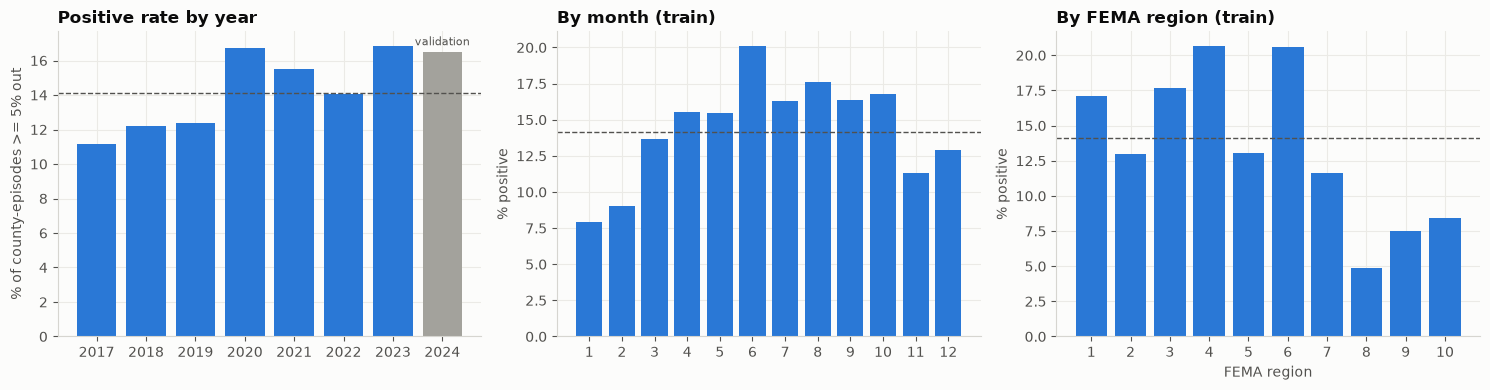

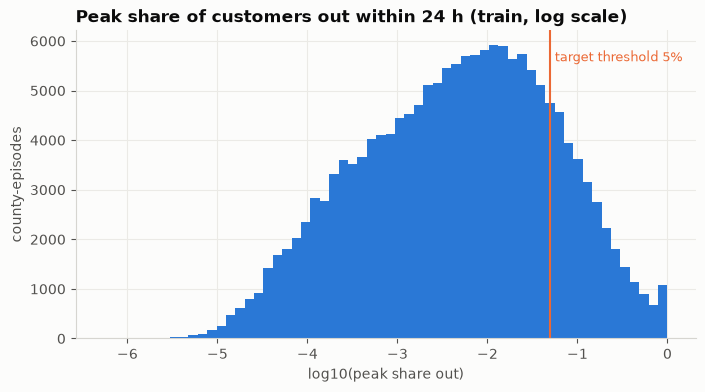

{'share_zero_peak': 0.22, 'share_ge_1pct': 0.32, 'share_ge_5pct': 0.141, 'share_ge_10pct': 0.083, 'share_ge_50pct': 0.012, 'median_peak_if_positive': 0.119}
highest states: {'LA': 0.375, 'MS': 0.289, 'GA': 0.274, 'ME': 0.255, 'WV': 0.252} | lowest: {'NM': 0.051, 'DE': 0.046, 'WY': 0.036, 'CO': 0.031, 'DC': 0.012}


In [5]:
# ---- 3. Target: how often, where, when -------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
yr = by_year.dropna(subset=["positive_rate"])
ax.bar(yr["year"].astype(str), 100 * yr["positive_rate"], color=[BLUE] * (len(yr) - 1) + [GRAY])
ax.axhline(100 * BASE, color=INK_2, lw=1, ls="--")
ax.set(title="Positive rate by year", ylabel="% of county-episodes >= 5% out")
ax.text(len(yr) - 1, 100 * yr["positive_rate"].iloc[-1] + 0.4, "validation", ha="center", fontsize=8, color=INK_2)

ax = axes[1]
m = train.groupby("month")["target"].mean()
ax.bar(m.index, 100 * m.values, color=BLUE)
ax.axhline(100 * BASE, color=INK_2, lw=1, ls="--")
ax.set(title="By month (train)", xticks=range(1, 13), ylabel="% positive")

ax = axes[2]
r = train.groupby("fema_region")["target"].agg(["mean", "size"])
ax.bar(r.index.astype(str), 100 * r["mean"], color=BLUE)
ax.axhline(100 * BASE, color=INK_2, lw=1, ls="--")
ax.set(title="By FEMA region (train)", xlabel="FEMA region", ylabel="% positive")
fig.tight_layout()
save(fig, "01_target_by_year_month_region")

# Distribution of the label-defining peak (train): many zeros, long tail
peak = train["retro_peak_24h"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(peak[peak > 0]), bins=60, color=BLUE)
ax.axvline(np.log10(0.05), color=ORANGE, lw=1.5)
ax.text(np.log10(0.05) + 0.05, ax.get_ylim()[1] * 0.9, "target threshold 5%", color=ORANGE, fontsize=9)
ax.set(title="Peak share of customers out within 24 h (train, log scale)", xlabel="log10(peak share out)", ylabel="county-episodes")
save(fig, "02_peak_share_distribution")

peak_summary = pd.Series({"share_zero_peak": (peak == 0).mean(), "share_ge_1pct": (peak >= 0.01).mean(),
                          "share_ge_5pct": (peak >= 0.05).mean(), "share_ge_10pct": (peak >= 0.10).mean(),
                          "share_ge_50pct": (peak >= 0.50).mean(), "median_peak_if_positive": peak[train["target"] == 1].median()})
target_tables = {"by_month": m, "by_fema_region": r["mean"]}
pd.concat(target_tables, axis=1).to_csv(TABLES / "target_by_month_region.csv")
peak_summary.to_frame("value").to_csv(TABLES / "peak_summary.csv")
state_rate = train.groupby("state_abbr")["target"].agg(rate="mean", rows="size").sort_values("rate", ascending=False)
state_rate.to_csv(TABLES / "target_by_state.csv")
print(peak_summary.round(3).to_dict())
print("highest states:", state_rate.head(5)["rate"].round(3).to_dict(), "| lowest:", state_rate.tail(5)["rate"].round(3).to_dict())

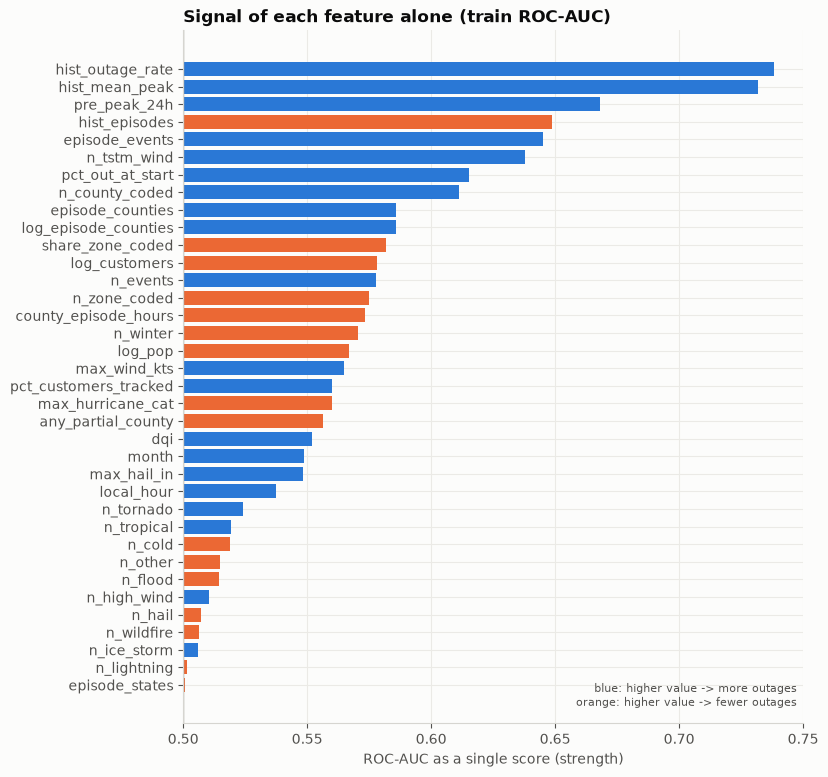

,feature,group,auc,strength,direction,coverage_pct,spearman
0,hist_outage_rate,history,0.738,0.738,higher -> more outages,100.000,0.287
1,hist_mean_peak,history,0.732,0.732,higher -> more outages,100.000,0.279
2,pre_peak_24h,pre-storm,0.668,0.668,higher -> more outages,96.678,0.206
3,hist_episodes,history,0.351,0.649,higher -> fewer outages,100.000,-0.179
4,episode_events,storm,0.645,0.645,higher -> more outages,100.000,0.175
5,n_tstm_wind,storm,0.638,0.638,higher -> more outages,100.000,0.209
6,pct_out_at_start,pre-storm,0.615,0.615,higher -> more outages,96.678,0.159
7,n_county_coded,storm,0.611,0.611,higher -> more outages,100.000,0.145
8,episode_counties,storm,0.586,0.586,higher -> more outages,100.000,0.104
9,log_episode_counties,storm,0.586,0.586,higher -> more outages,100.000,0.104


In [6]:
# ---- 4. Feature-target signal: one feature at a time (train) ---------------------------
# ROC-AUC of each feature used alone as a score (on rows where it is present).
# 0.5 = no signal; values below 0.5 mean "higher value -> lower risk", so strength = |AUC - 0.5|.
sig = []
for col in FEATURES:
    x = as_num(train[col])
    ok = x.notna()
    auc = roc_auc_score(train.loc[ok, "target"], x[ok]) if x[ok].nunique() > 1 else np.nan
    sig.append({"feature": col, "group": DICT[col][0], "auc": auc, "strength": abs(auc - 0.5) + 0.5,
                "direction": "higher -> more outages" if auc >= 0.5 else "higher -> fewer outages",
                "coverage_pct": 100 * ok.mean(), "spearman": x.corr(train["target"], method="spearman")})
signal = pd.DataFrame(sig).sort_values("strength", ascending=False).reset_index(drop=True)
signal.to_csv(TABLES / "univariate_signal.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 9))
s = signal.iloc[::-1]
ax.barh(s["feature"], s["strength"] - 0.5, left=0.5, color=[BLUE if d.startswith("higher -> more") else ORANGE for d in s["direction"]])
ax.axvline(0.5, color=GRAY, lw=1)
ax.set(title="Signal of each feature alone (train ROC-AUC)", xlabel="ROC-AUC as a single score (strength)", xlim=(0.5, None))
ax.text(0.99, 0.02, "blue: higher value -> more outages\norange: higher value -> fewer outages", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, color=INK_2)
save(fig, "03_univariate_signal")
signal.round(3).head(15)

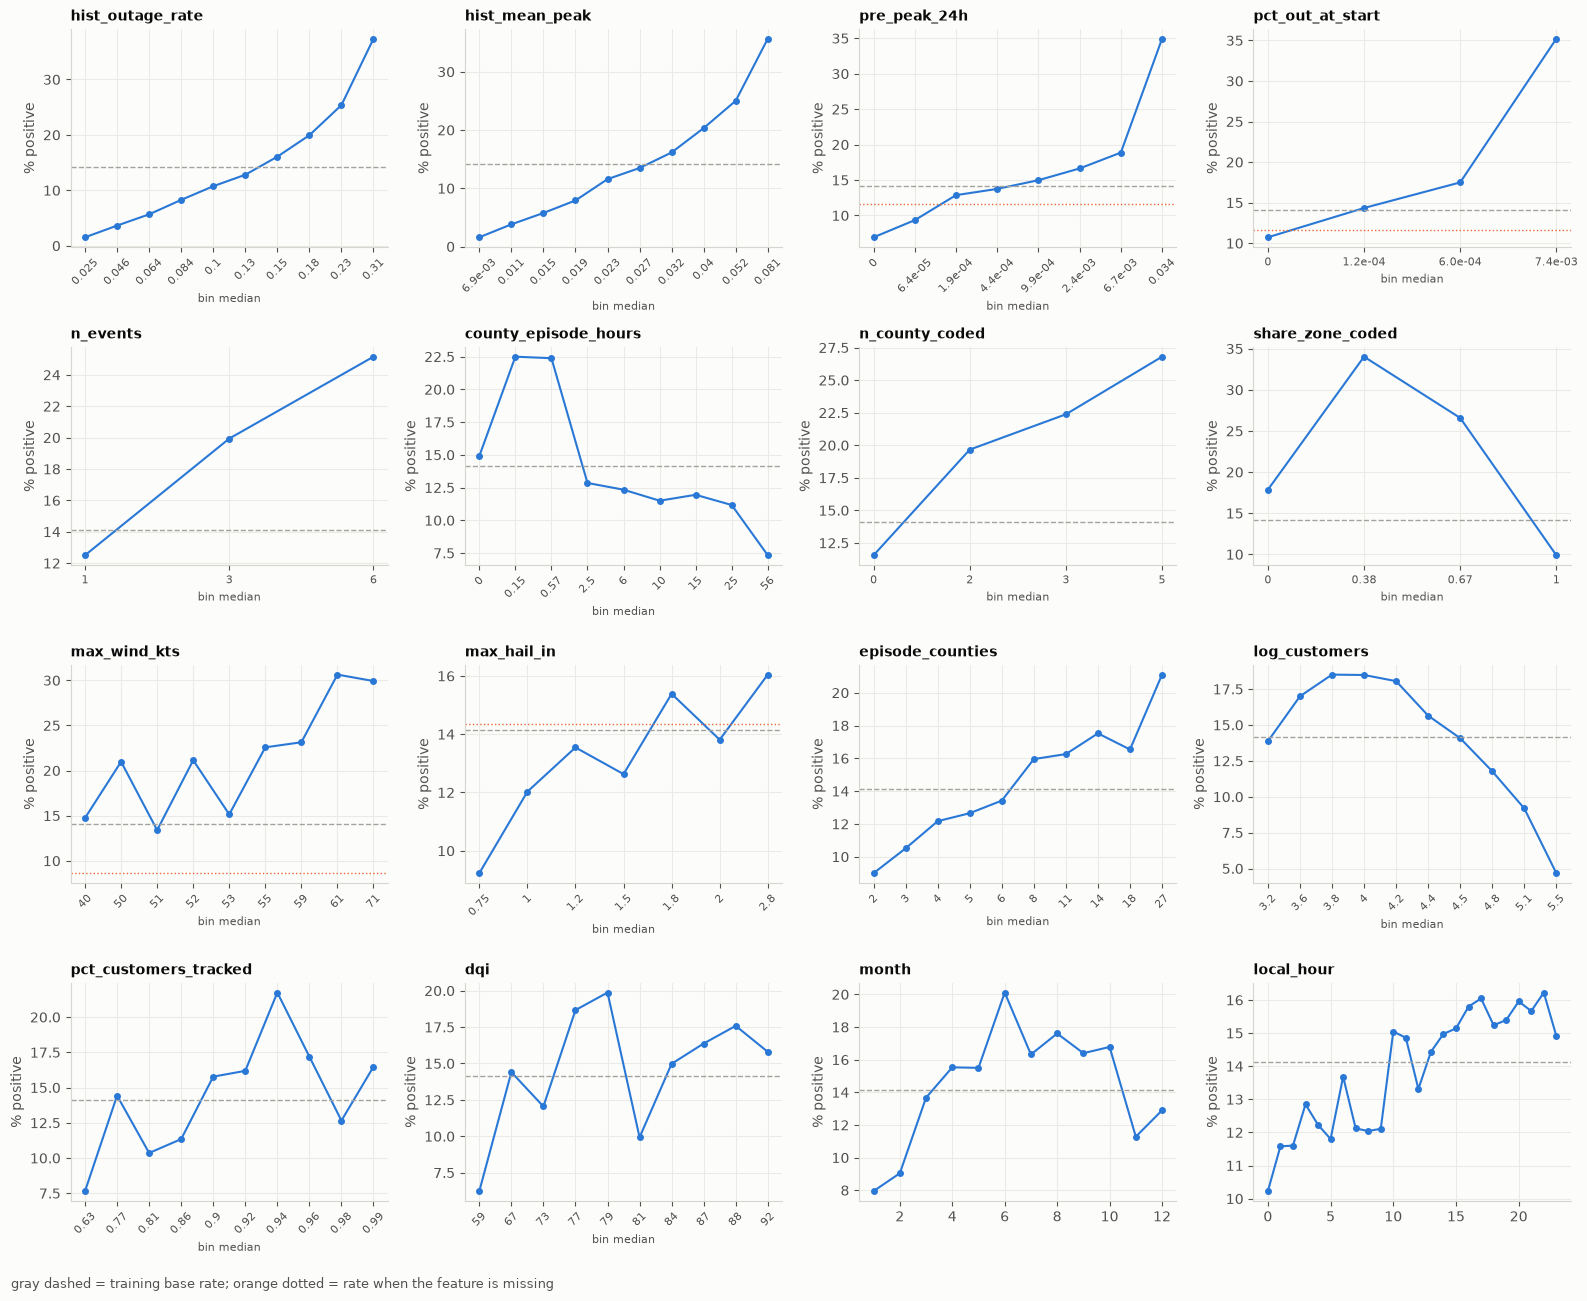

In [7]:
# ---- 5. Outage rate across each feature's range (train) ----------------------------------
# Quantile bins (up to 10) of the present values; tied values stay in one bin, so zero-heavy and
# count features get fewer bins. Bins are evenly spaced on the x axis and labelled with their median.
# The dashed line is the training base rate.
CURVES = ["hist_outage_rate", "hist_mean_peak", "pre_peak_24h", "pct_out_at_start",
          "n_events", "county_episode_hours", "n_county_coded", "share_zone_coded",
          "max_wind_kts", "max_hail_in", "episode_counties", "log_customers",
          "pct_customers_tracked", "dqi", "month", "local_hour"]


def short(v):
    """Compact tick label for a bin median."""
    return f"{v:.0f}" if abs(v) >= 10 or float(v).is_integer() else (f"{v:.2g}" if abs(v) >= 0.01 else f"{v:.1e}")


curve_rows = []
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, col in zip(axes.flat, CURVES):
    x, y = as_num(train[col]), train["target"]
    ok = x.notna()
    if col in ("month", "local_hour"):
        g = y[ok].groupby(x[ok]).agg(["mean", "size"])
        g["x"] = g.index
        ax.plot(g["x"], 100 * g["mean"], "o-", color=BLUE, ms=4)
    else:
        if col == "share_zone_coded":   # almost always exactly 0 or 1
            bins = pd.cut(x[ok], [-0.001, 0, 0.5, 0.999, 1])
        else:
            bins = pd.qcut(x[ok], 10, duplicates="drop") if x[ok].nunique() > 10 else x[ok]
        g = pd.DataFrame({"x": x[ok], "y": y[ok], "b": bins}).groupby("b", observed=True).agg(x=("x", "median"), mean=("y", "mean"), size=("y", "size"))
        ax.plot(range(len(g)), 100 * g["mean"], "o-", color=BLUE, ms=4)
        ax.set_xticks(range(len(g)), [short(v) for v in g["x"]], fontsize=8, rotation=45 if len(g) > 6 else 0)
        ax.set_xlabel("bin median", fontsize=8)
    if (~ok).mean() > 0.01:   # rate for rows where the feature is missing
        ax.axhline(100 * y[~ok].mean(), color=ORANGE, lw=1, ls=":")
    ax.axhline(100 * BASE, color=GRAY, lw=1, ls="--")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("% positive")
    for _, rr in g.iterrows():
        curve_rows.append({"feature": col, "x": rr["x"], "rate": rr["mean"], "rows": rr["size"]})
fig.text(0.01, 0.005, "gray dashed = training base rate; orange dotted = rate when the feature is missing", fontsize=9, color=INK_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
save(fig, "04_rate_by_feature_bins")
pd.DataFrame(curve_rows).to_csv(TABLES / "rate_by_feature_bins.csv", index=False)

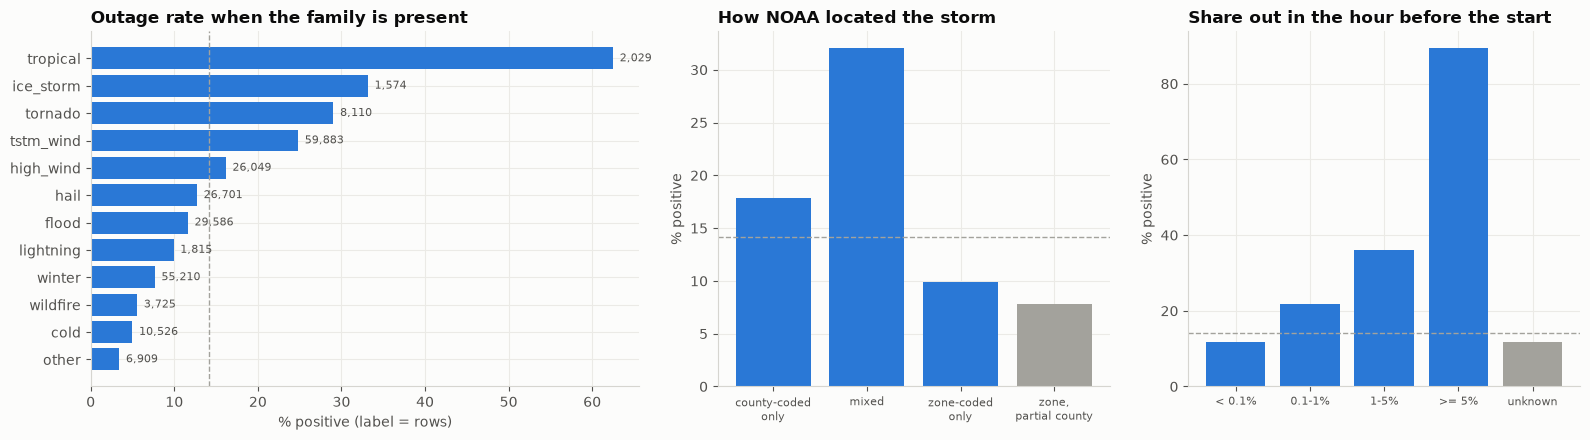

,family,rows,rate,rate_only_family
11,other,6909,0.034,0.019
8,cold,10526,0.050,0.044
10,wildfire,3725,0.056,0.042
5,winter,55210,0.077,0.074
9,lightning,1815,0.099,0.051
4,flood,29586,0.116,0.082
1,hail,26701,0.127,0.069
3,high_wind,26049,0.162,0.150
0,tstm_wind,59883,0.248,0.241
2,tornado,8110,0.290,0.200


,rate,rows
county-coded only,0.179,104315
mixed,0.320,2366
zone-coded only,0.099,101801
"zone, partial county",0.078,45129


,rate,rows
pct_out_at_start,,
< 0.1%,0.117,176457
0.1-1%,0.217,16697
1-5%,0.361,5807
>= 5%,0.894,2596
unknown (day before unobserved),0.116,6925


In [8]:
# ---- 6. Storm families and how the storm was located (train) ------------------------------
FAMS = ["tstm_wind", "hail", "tornado", "high_wind", "flood", "winter", "ice_storm", "tropical", "cold", "lightning", "wildfire", "other"]
fam = pd.DataFrame([{"family": f, "rows": int((train[f"n_{f}"] > 0).sum()), "rate": train.loc[train[f"n_{f}"] > 0, "target"].mean(),
                     "rate_only_family": train.loc[(train[f"n_{f}"] > 0) & (train[[f"n_{o}" for o in FAMS if o != f]].sum(axis=1) == 0), "target"].mean()}
                    for f in FAMS]).sort_values("rate")
fam.to_csv(TABLES / "rate_by_storm_family.csv", index=False)

coding = np.select([train["share_zone_coded"] == 0, train["share_zone_coded"] == 1], ["county-coded only", "zone-coded only"], "mixed")
loc = train.groupby(coding)["target"].agg(rate="mean", rows="size")
loc.loc["zone, partial county"] = [train.loc[train["any_partial_county"], "target"].mean(), int(train["any_partial_county"].sum())]
loc.to_csv(TABLES / "rate_by_storm_coding.csv")

pre = pd.cut(train["pct_out_at_start"], [-0.001, 0.001, 0.01, 0.05, 1.0], labels=["< 0.1%", "0.1-1%", "1-5%", ">= 5%"])
pre_t = train.groupby(pre, observed=True)["target"].agg(rate="mean", rows="size")
pre_t.loc["unknown (day before unobserved)"] = [train.loc[train["pct_out_at_start"].isna(), "target"].mean(), int(train["pct_out_at_start"].isna().sum())]
pre_t.to_csv(TABLES / "rate_by_pre_storm_outage.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax = axes[0]
ax.barh(fam["family"], 100 * fam["rate"], color=BLUE)
for i, (rt, n) in enumerate(zip(fam["rate"], fam["rows"])):
    ax.text(100 * rt + 0.8, i, f"{n:,}", va="center", fontsize=8, color=INK_2)
ax.axvline(100 * BASE, color=GRAY, lw=1, ls="--")
ax.set(title="Outage rate when the family is present", xlabel="% positive (label = rows)")
ax = axes[1]
ax.bar(range(len(loc)), 100 * loc["rate"], color=[BLUE, BLUE, BLUE, GRAY][: len(loc)])
ax.set_xticks(range(len(loc)), [t.replace(", ", ",\n").replace(" only", "\nonly") for t in loc.index], fontsize=8)
ax.axhline(100 * BASE, color=GRAY, lw=1, ls="--")
ax.set(title="How NOAA located the storm", ylabel="% positive")
ax = axes[2]
ax.bar(range(len(pre_t)), 100 * pre_t["rate"], color=[BLUE] * (len(pre_t) - 1) + [GRAY])
ax.set_xticks(range(len(pre_t)), [t.replace(" (day before unobserved)", "") for t in pre_t.index], fontsize=8)
ax.axhline(100 * BASE, color=GRAY, lw=1, ls="--")
ax.set(title="Share out in the hour before the start", ylabel="% positive")
fig.tight_layout()
save(fig, "05_family_coding_prestorm")
display(fam.round(3), loc.round(3), pre_t.round(3))

In [9]:
# ---- 7. Missing values and what they mean (train) ---------------------------------------
miss = []
for col in FEATURES:
    na = train[col].isna()
    if na.any():
        miss.append({"feature": col, "missing_pct": 100 * na.mean(), "rate_when_missing": train.loc[na, "target"].mean(),
                     "rate_when_present": train.loc[~na, "target"].mean()})
missing = pd.DataFrame(miss).sort_values("missing_pct", ascending=False)
missing.to_csv(TABLES / "missingness_vs_target.csv", index=False)
missing.round(3)

,feature,missing_pct,rate_when_missing,rate_when_present
2,max_hurricane_cat,99.922,0.141,0.902
1,max_hail_in,87.193,0.143,0.127
0,max_wind_kts,59.048,0.086,0.221
4,pre_peak_24h,3.322,0.116,0.142
5,pct_out_at_start,3.322,0.116,0.142
3,log_pop,0.362,0.113,0.141


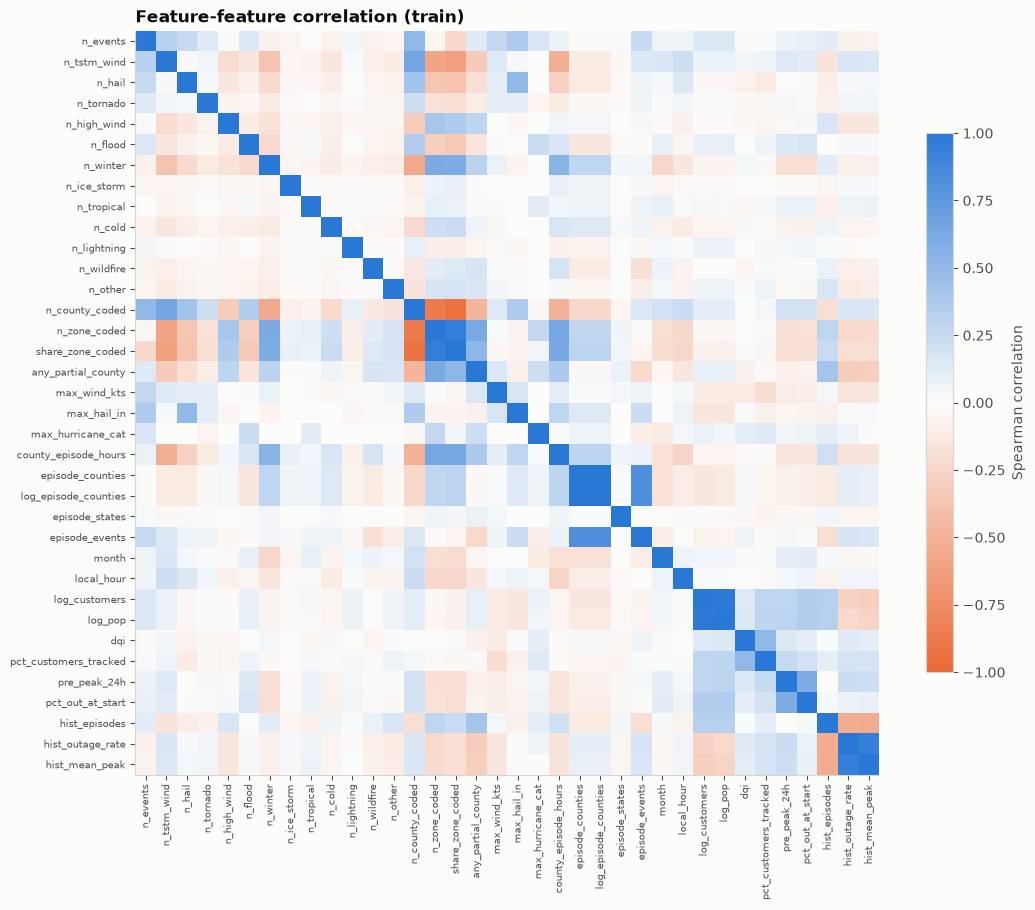

,feature_a,feature_b,spearman
778,episode_counties,log_episode_counties,1.000
1000,log_customers,log_pop,0.980
519,n_zone_coded,share_zone_coded,0.949
1259,hist_outage_rate,hist_mean_peak,0.944
483,n_county_coded,share_zone_coded,-0.927
482,n_county_coded,n_zone_coded,-0.866
816,log_episode_counties,episode_events,0.825
780,episode_counties,episode_events,0.825
49,n_tstm_wind,n_county_coded,0.653
524,n_zone_coded,county_episode_hours,0.638


In [10]:
# ---- 8. Redundancy between features (train, Spearman) -------------------------------------
X = pd.DataFrame({c: as_num(train[c]) for c in FEATURES})
corr = X.corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("spearman").reset_index()
pairs.columns = ["feature_a", "feature_b", "spearman"]
pairs = pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index)
pairs.head(40).to_csv(TABLES / "top_correlated_pairs.csv", index=False)

cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#fcfcfb", BLUE])
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Feature-feature correlation (train)")
save(fig, "06_feature_correlation")
pairs.head(12).round(3)

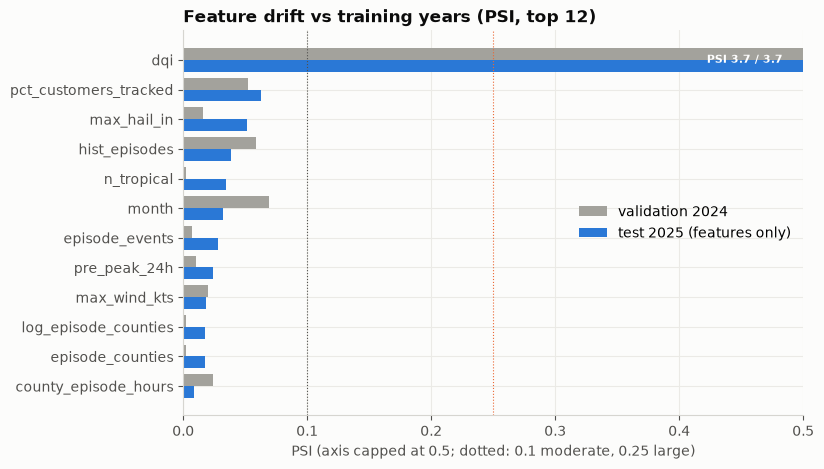

,feature,group,psi_validation,psi_test,mean_train,mean_validation,mean_test
19,max_hurricane_cat,storm,0.197,8.064,1.761,1.441,NaN
29,dqi,county,3.694,3.748,78.189,84.548,84.777
30,pct_customers_tracked,county,0.053,0.063,0.868,0.884,0.885
18,max_hail_in,storm,0.016,0.051,1.290,1.363,1.368
33,hist_episodes,history,0.059,0.038,86.628,101.562,97.181
8,n_tropical,storm,0.002,0.034,0.012,0.020,0.000
25,month,time,0.069,0.032,5.713,5.405,5.434
24,episode_events,storm,0.007,0.028,15.460,16.703,18.478
31,pre_peak_24h,pre-storm,0.010,0.024,0.009,0.009,0.010
17,max_wind_kts,storm,0.020,0.019,54.032,54.605,54.835


In [11]:
# ---- 9. Drift between splits (features only) -------------------------------------------
# Population stability index (PSI) of each feature vs the training distribution, using training deciles.
# Rule of thumb: < 0.1 stable, 0.1-0.25 moderate shift, > 0.25 large shift.
def psi(ref, new, bins=10):
    ref, new = ref.dropna(), new.dropna()
    if ref.nunique() <= bins:   # few distinct values: compare value shares directly
        cats = sorted(set(ref.unique()) | set(new.unique()))
        p = ref.value_counts(normalize=True).reindex(cats, fill_value=0)
        q = new.value_counts(normalize=True).reindex(cats, fill_value=0)
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        p = pd.Series(np.histogram(ref, edges)[0] / len(ref))
        q = pd.Series(np.histogram(new, edges)[0] / len(new))
    p, q = p.clip(lower=1e-4), q.clip(lower=1e-4)
    return float(((q - p) * np.log(q / p)).sum())


drift = pd.DataFrame([{"feature": c, "group": DICT[c][0],
                       "psi_validation": psi(as_num(train[c]), as_num(val[c])), "psi_test": psi(as_num(train[c]), as_num(test[c])),
                       "mean_train": as_num(train[c]).mean(), "mean_validation": as_num(val[c]).mean(), "mean_test": as_num(test[c]).mean()}
                      for c in FEATURES]).sort_values("psi_test", ascending=False)
drift.to_csv(TABLES / "feature_drift_psi.csv", index=False)

# max_hurricane_cat is 99.9% empty, so its PSI compares a handful of rows and is left out of the chart
top = drift[~drift["feature"].eq("max_hurricane_cat")].head(12).iloc[::-1]
XMAX = 0.5
fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(top))
ax.barh(yy + 0.2, top["psi_validation"].clip(upper=XMAX), height=0.4, color=GRAY, label="validation 2024")
ax.barh(yy - 0.2, top["psi_test"].clip(upper=XMAX), height=0.4, color=BLUE, label="test 2025 (features only)")
for i, (pv, pt) in enumerate(zip(top["psi_validation"], top["psi_test"])):
    if max(pv, pt) > XMAX:
        ax.text(XMAX * 0.98, i, f"PSI {pv:.1f} / {pt:.1f}  ", ha="right", va="center", fontsize=8, color="white", fontweight="bold")
ax.set_yticks(yy, top["feature"])
ax.axvline(0.1, color=INK_2, lw=0.8, ls=":")
ax.axvline(0.25, color=ORANGE, lw=0.8, ls=":")
ax.set(title="Feature drift vs training years (PSI, top 12)", xlabel="PSI (axis capped at 0.5; dotted: 0.1 moderate, 0.25 large)", xlim=(0, XMAX))
ax.legend(loc="center right")
save(fig, "07_feature_drift_psi")
drift.round(3).head(12)

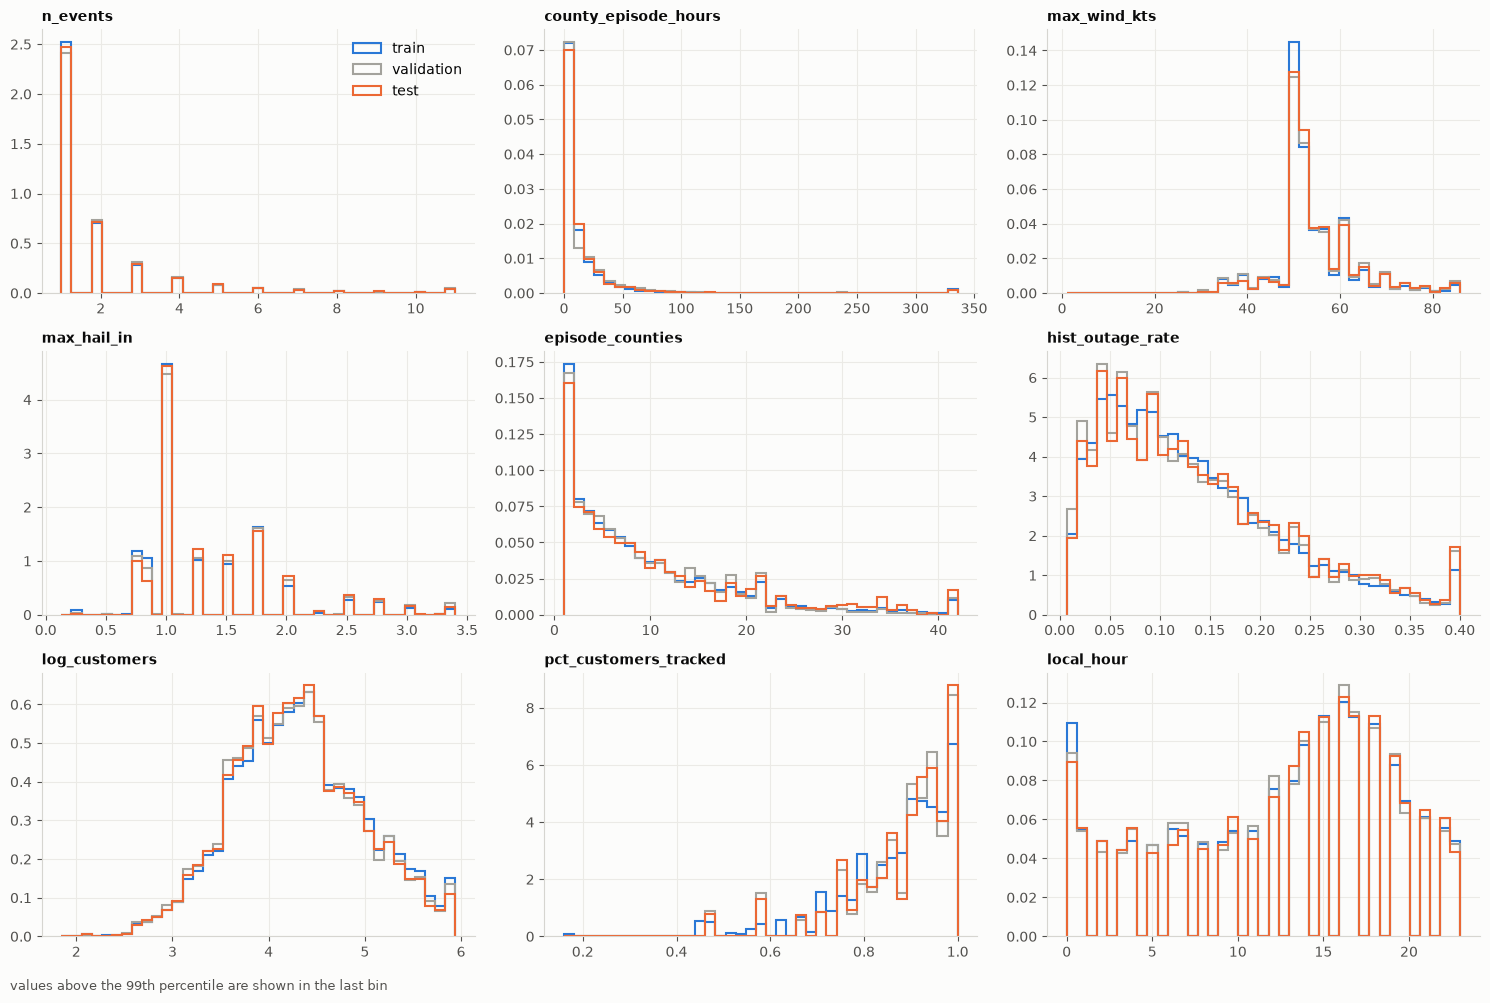

In [12]:
# ---- 10. Key distributions (train vs validation vs test features) -------------------------
DIST = ["n_events", "county_episode_hours", "max_wind_kts", "max_hail_in", "episode_counties", "hist_outage_rate",
        "log_customers", "pct_customers_tracked", "local_hour"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, DIST):
    data = [as_num(d[col]).dropna() for d in (train, val, test)]
    lo, hi = np.nanquantile(pd.concat(data), [0.0, 0.99])
    edges = np.linspace(lo, hi, 40)
    for d, color, lab in zip(data, [BLUE, GRAY, ORANGE], ["train", "validation", "test"]):
        ax.hist(d.clip(upper=hi), bins=edges, density=True, histtype="step", lw=1.5, color=color, label=lab)
    ax.set_title(col, fontsize=10)
axes.flat[0].legend()
fig.text(0.01, 0.005, "values above the 99th percentile are shown in the last bin", fontsize=9, color=INK_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
save(fig, "08_feature_distributions_by_split")

In [13]:
# ---- 11. Checks -------------------------------------------------------------------
checks = pd.DataFrame([
    ("one row per county x episode (all splits)", not pd.concat([train, val, test])[["fips", "episode_id"]].duplicated().any()),
    ("no missing target (train, validation)", train["target"].notna().all() and val["target"].notna().all()),
    ("target matches retro_peak_24h >= 5%", bool(((train["retro_peak_24h"] >= 0.05).astype(int) == train["target"]).all())),
    ("no retro_ column among features", not any(c.startswith("retro_") for c in FEATURES)),
    ("test file holds no target", "target" not in test.columns),
    ("split years don't overlap", train["year"].max() < val["year"].min() <= val["year"].max() < test["year"].min()),
    ("feature dictionary covers every column", set(DICT) == set(train.columns)),
], columns=["check", "passed"])
checks.to_csv(TABLES / "checks.csv", index=False)
assert checks["passed"].all()
checks

,check,passed
0,one row per county x episode (all splits),True
1,"no missing target (train, validation)",True
2,target matches retro_peak_24h >= 5%,True
3,no retro_ column among features,True
4,test file holds no target,True
5,split years don't overlap,True
6,feature dictionary covers every column,True
